#### Importaciones y descarga única de datos oficiales

In [ ]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.table import Table
from astropy.coordinates import SkyCoord, EarthLocation
from regions import CircleSkyRegion
from gammapy.data import FixedPointingInfo, Observation
from gammapy.datasets import SpectrumDataset
from gammapy.makers import SpectrumDatasetMaker
from gammapy.maps import MapAxis, RegionGeom
from gammapy.irf import load_irf_dict_from_file
from gammapy.modeling.models import PowerLawSpectralModel, SkyModel
from gammapy.stats import WStatCountsStatistic

# Descarga única desde fuentes oficiales (con verificación SSL activa)
archivos_oficiales = {
    "4FHL_catalog.fit": "https://fermi.gsfc.nasa.gov/ssc/data/access/lat/4FHL/gll_psch_v14.fit", #catálogo 4FHL de Fermi-LAT (formato FITS)
    "irf_file.fits": "https://raw.githubusercontent.com/gammapy/gammapy-data/master/cta-1dc/caldb/data/cta/1dc/bcf/South_z20_50h/irf_file.fits", #IRF de CTA-South (formato FITS)
}

for nombre_local, url_oficial in archivos_oficiales.items():
    if not os.path.exists(nombre_local):
        print(f"Descargando {nombre_local} desde fuente oficial...")
        urllib.request.urlretrieve(url_oficial, nombre_local)
        print(f"✅ {nombre_local} guardado en el servidor.")
    else:
        print(f"✅ {nombre_local} ya existe en el servidor (no se vuelve a descargar).")

Descargando 4FHL_catalog.fit desde fuente oficial...
✅ 4FHL_catalog.fit guardado en el servidor.
Descargando irf_file.fits desde fuente oficial...
✅ irf_file.fits guardado en el servidor.


# PASO 0: DIBUJAR EL ESPECTRO DE LAS FUENTES DEL CATÁLOGO 4FHL

ANA! Simplifica las celdas como te lo dice el gemini. no hace falta q incluyas todos los pasos. haz directamente lo de dibujar el espectro junto con las bandas de mariposa. y como ejemplo usar directamente la misma fuente brillante q mas tarde usaremos para el estudio de detectabilidad.

una vez hechas estas correcciones al código q ya teníamos, hacer las cosas q nos ha mandado el profe, ya sobre vs code.

(Dibujar el flujo de fotones (dN/dE), sirve para saber cuántos fotones llegan a cada energía).

In [ ]:
# Esto es solo para bichear un poco el contenido del catálogo 4FHL descargado, no es necesario para el análisis principal.
# Abrir el archivo FITS con Astropy para explorar su contenido
hdul = fits.open(archivo_fits)
# Mostrar la estructura del archivo FITS (HDUs)
print("--- Estructura del archivo FITS ---")
hdul.info()

--- Estructura del archivo FITS ---
Filename: 4FHL_catalog.fit
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   ()      
  1  4FHL Source Catalog    1 BinTableHDU    150   673R x 36C   [18A, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, I, 28A, E, E, 8A, E, 18A, 18A, 18A, 28A]   
  2  Extended Sources    1 BinTableHDU     54   55R x 11C   [18A, 28A, E, E, E, E, 25A, E, E, I, 25A]   
  3  ROIs          1 BinTableHDU     58   154R x 12C   [I, E, E, E, E, E, E, E, E, E, E, E]   


In [ ]:
# 1. Cargar la tabla principal (usualmente está en la extensión 1)
catalogo = Table(hdul[1].data)

# Mostrar todos los nombres de las columnas del catálogo
print("\n--- Columnas disponibles en el catálogo ---")
print(catalogo.colnames)


--- Columnas disponibles en el catálogo ---
['Source_Name', 'RAJ2000', 'DEJ2000', 'GLON', 'GLAT', 'Pos_err_68', 'Pos_err_95', 'TS', 'PL_Index', 'Unc_PL_Index', 'Flux50', 'Unc_Flux50', 'Energy_Flux50', 'Unc_Energy_Flux50', 'Flux50_171GeV', 'Unc_Flux50_171GeV', 'Sqrt_TS50_171GeV', 'Flux171_585GeV', 'Unc_Flux171_585GeV', 'Sqrt_TS171_585GeV', 'Flux585_2000GeV', 'Unc_Flux585_2000GeV', 'Sqrt_TS585_2000GeV', 'Npred', 'HEP_Energy', 'HEP_Prob', 'ROI', 'ASSOC', 'ASSOC_PROB_BAY', 'ASSOC_PROB_LR', 'CLASS', 'Redshift', '4FGL', '2FHL', '3FHL', 'TeV']


Ahora definimos la función que, dándole el nombre de la fuente espectral, buscará la fuente en el catálogo y dibujará el espectro en escala log-log.

Tenemos en cuenta que la energía base del catálogo 4FHL son 50 GeV.

Suponiendo que en el catálogo tenemos los 3 tipos de espectros: (ahora veremos que esto no es verdad)

In [ ]:
def dibujar_espectro(nombre_fuente, catalogo):
    # 1. Extraemos y limpiamos los nombres (los FITS suelen tener espacios ocultos al final)
    nombres = np.array([name.strip() for name in catalogo['Source_Name']])

    # 2. Comprobar si la fuente existe
    if nombre_fuente not in nombres:
        print(f"❌ Error: No se encontró la fuente '{nombre_fuente}'.")
        print(f"Sugerencias de nombres válidos (primeros 5): {nombres[:5]}")
        return

    # 3. Seleccionamos la fila de nuestra fuente
    idx = np.where(nombres == nombre_fuente)[0][0]
    fuente = catalogo[idx]
    print(f"✅ Fuente encontrada: {nombre_fuente}")

    # 4. Función auxiliar para encontrar nombres de columnas (evitar errores de mayúsculas/espacios)
    def encontrar_columna(nombres_posibles):
        for col in catalogo.colnames:
            if col.strip().lower() in [n.lower() for n in nombres_posibles]:
                return col
        return None

    # Buscamos los nombres exactos en el archivo FITS
    col_tipo = encontrar_columna(['SpectrumType', 'Spectrum_Type', 'Model'])
    col_pivote = encontrar_columna(['Pivot_Energy', 'PivotEnergy', 'e0'])
    col_pl_index = encontrar_columna(['PL_Index', 'Spectral_Index', 'Index1'])
    col_lp_index = encontrar_columna(['LP_Index', 'alpha', 'Index1'])
    col_lp_beta = encontrar_columna(['LP_beta', 'beta'])
    col_cutoff = encontrar_columna(['Cutoff_Energy', 'Exp_Index', 'Energy_Cutoff'])

    # 5. Extraer el tipo espectral (si no existe la columna, es PowerLaw por defecto)
    tipo_espectral = fuente[col_tipo].strip() if col_tipo else 'PowerLaw'

    # Extraer la energía pivote (si no existe, usamos 50 GeV que es el límite del 4FHL)
    E0 = fuente[col_pivote] if col_pivote else 50000.0

    print(f"Tipo espectral: {tipo_espectral}")

    # 6. Generar el rango de energías para el eje X (de 50 GeV a 2 TeV = 50,000 a 2,000,000 MeV)
    E = np.logspace(np.log10(50000), np.log10(2000000), 100)

    # 7. Calcular la curva según el tipo de espectro
    if tipo_espectral == 'PowerLaw':
        # Ley de potencias simple: recta en log-log
        indice = fuente[col_pl_index]
        flujo_forma = (E / E0)**(-indice)

    elif tipo_espectral == 'LogParabola':
        # Curvatura suave
        indice = fuente[col_lp_index]
        beta = fuente[col_lp_beta]
        flujo_forma = (E / E0)**(-indice - beta * np.log(E / E0))

    elif tipo_espectral == 'PLSuperExpCutoff':
        # Ley de potencias que cae abruptamente (corte exponencial por atenuación EBL u otros procesos)
        indice = fuente[col_pl_index]
        # Si no encontramos la columna de la energía de corte, asumimos un valor estándar para evitar errores de graficado
        E_cut = fuente[col_cutoff] if col_cutoff else 500000.0
        # Ecuación estándar de Fermi para el corte exponencial
        flujo_forma = (E / E0)**(-indice) * np.exp((E0 / E_cut) - (E / E_cut))

    else:
        print(f"⚠️ El modelo '{tipo_espectral}' no está contemplado en la función.")
        return

    # 7. Dibujar el espectro en diagrama log-log
    plt.figure(figsize=(8, 6))

    # Pasamos la energía a GeV (dividiendo entre 1000) para que el eje sea más legible
    plt.plot(E / 1000, flujo_forma, color='crimson', lw=2, label=f'Modelo: {tipo_espectral}')

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energía (GeV)', fontsize=12)
    plt.ylabel('Flujo Relativo $dE/dN$ (escala log)', fontsize=12)
    plt.title(f'Espectro de la fuente: {nombre_fuente}', fontsize=14, fontweight='bold')
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.legend()
    plt.show()

In [ ]:
# ==========================================
# PRUEBA DE LA FUNCIÓN: UNA PRUEBA PARA CADA TIPO DE ESPECTRO
# ==========================================
col_tipo_detectada = None
for col in catalogo.colnames:
    if col.strip().lower() in ['spectrumtype', 'spectrum_type', 'model']:
        col_tipo_detectada = col
        break

if col_tipo_detectada:
    # 1. Prueba PowerLaw (Ley de Potencias / Recta)
    fuentes_pl = catalogo[catalogo[col_tipo_detectada] == 'PowerLaw']
    if len(fuentes_pl) > 0:
        nombre_pl = fuentes_pl['Source_Name'][0].strip()
        print(f"\n--- 1. PRUEBA SPECTRO POWER-LAW ---")
        dibujar_espectro(nombre_pl, catalogo)

    # 2. Prueba LogParabola (Curva)
    fuentes_lp = catalogo[catalogo[col_tipo_detectada] == 'LogParabola']
    if len(fuentes_lp) > 0:
        nombre_lp = fuentes_lp['Source_Name'][0].strip()
        print(f"\n--- 2. PRUEBA ESPECTRO LOG-PARÁBOLA ---")
        dibujar_espectro(nombre_lp, catalogo)

    # 3. Prueba PLSuperExpCutoff (Recta que decae al final por atenuación)
    fuentes_cutoff = catalogo[catalogo[col_tipo_detectada] == 'PLSuperExpCutoff']
    if len(fuentes_cutoff) > 0:
        nombre_cutoff = fuentes_cutoff['Source_Name'][0].strip()
        print(f"\n--- 3. PRUEBA ESPECTRO CON CORTE EXPONENCIAL ---")
        dibujar_espectro(nombre_cutoff, catalogo)
    else:
        print("\nNota: Este subconjunto del catálogo 4FHL no contiene fuentes clasificadas como PLSuperExpCutoff en este archivo exacto, pero la función está lista para ellas.")
else:
    print("No se localizó la columna de tipo espectral.")

No se localizó la columna de tipo espectral.


Como vemos, en el catálogo no hay ninguna columna que incluya el tipo espectral de la fuente, ya que solo hay fuentes del tipo power-law. Esto pasa porque el catálogo 4FHL está enfocado exclusivamente en fuentes de muy alta energía (>50 GeV). A esas energías extremas, el número de fotones detectados por fuente es tan bajo que no hay suficiente estadística para ajustar modelos complejos; por ello, prácticamente todas las fuentes del 4FHL se modelan con una simple PowerLaw, y el archivo no incluye una columna de SpectrumType (a diferencia del catálogo general 4FGL).

Hagamos entonces una función suponiendo que solo hay un tipo de espectro en el catálogo, power-law (la función asume por defecto que la fuente es una power-law):

In [ ]:
def dibujar_espectro(nombre_fuente, catalogo):
    # 1. Limpieza de nombres
    nombres = np.array([name.strip() for name in catalogo['Source_Name']])

    if nombre_fuente not in nombres:
        print(f"❌ Error: No se encontró la fuente '{nombre_fuente}'.")
        return

    idx = np.where(nombres == nombre_fuente)[0][0]
    fuente = catalogo[idx]
    print(f"✅ Fuente encontrada: {nombre_fuente}")

    # 2. Configuración para 4FHL (por defecto PowerLaw al ser alta energía)
    tipo_espectral = 'PowerLaw'
    E0 = 50000.0 # 50 GeV en MeV (energía de referencia estándar del 4FHL)

    # Buscamos el índice espectral (PL_Index) de forma segura
    col_pl_index = None
    for col in catalogo.colnames:
        if 'pl_index' in col.lower() or 'index' in col.lower():
            col_pl_index = col
            break

    indice = fuente[col_pl_index] if col_pl_index else 2.0
    print(f"Tipo espectral: {tipo_espectral} (Índice Gamma: {indice:.2f})")

    # 3. Rango de energías: de 50 GeV (50,000 MeV) a 2 TeV (2,000,000 MeV)
    E = np.logspace(np.log10(50000), np.log10(2000000), 100)

    # 4. Cálculo del flujo (Ley de potencias)
    flujo_forma = (E / E0)**(-indice)

    # 5. Dibujar el espectro en escala log-log
    plt.figure(figsize=(8, 6))
    plt.plot(E / 1000, flujo_forma, color='crimson', lw=2, label=f'Modelo: {tipo_espectral} (Indice: {indice:.2f})')

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energía (GeV)', fontsize=12)
    plt.ylabel('Flujo Relativo $dE/dN$ (escala log)', fontsize=12)
    plt.title(f'Espectro de la fuente: {nombre_fuente}', fontsize=14, fontweight='bold')
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.legend()
    plt.show()

✅ Fuente encontrada: 4FHL J0001.4-4153
Tipo espectral: PowerLaw (Índice Gamma: 2.83)


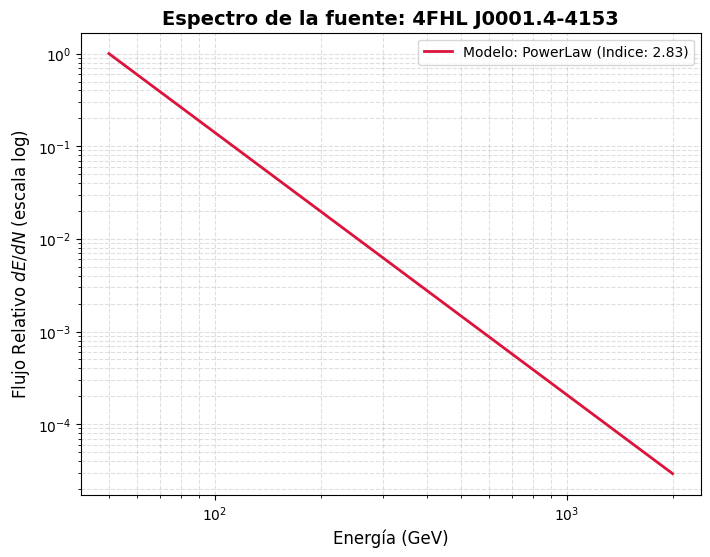

In [ ]:
# --- PRUEBA DE LA FUNCIÓN ---
# Cogemos el nombre de la primera fuente del catálogo y lo pasamos por la función
nombre_prueba = catalogo['Source_Name'][0].strip()
dibujar_espectro(nombre_prueba, catalogo)

# PASO 1: DIBUJAR LA DENSIDAD DE ENERGÍA ESPECTRAL (SED) CON SU INCERTIDUMBRE (BANDAS DE MARIPOSA)

(Para ver en qué energías emite con más intensidad la fuente y preparar el estudio de detectabilidad)

In [ ]:
# 1. Asegurarnos de que astropy y las herramientas gráficas están instaladas
#!pip install astropy matplotlib numpy

# 2. Importar las librerías que vamos a necesitar
import os
import ssl
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table

# 3. URL directa del catálogo 4FHL de Fermi-LAT (formato FITS)
url_4fhl = "https://fermi.gsfc.nasa.gov/ssc/data/access/lat/4FHL/gll_psch_v14.fit"
archivo_fits = "4FHL_catalog.fit"

# Ignoramos la verificación SSL para que urllib no te dé el error de certificado de la NASA
ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

# 4. Descargar el archivo
if not os.path.exists(archivo_fits):
    print("Descargando el catálogo 4FHL...")
    with urllib.request.urlopen(url_4fhl, context=ctx) as u, open(archivo_fits, 'wb') as f:
        f.write(u.read())
    print("¡Descarga completada con éxito!\n")

# 5. Abrir el archivo FITS con Astropy para explorar su contenido
hdul = fits.open(archivo_fits)
catalogo = Table(hdul[1].data)
print("¡Catálogo cargado en la variable 'catalogo'!")

¡Catálogo cargado en la variable 'catalogo'!


Al extrapolar los espectros de Fermi a altas energías (IACT), debemos tener en cuenta la incertidumbre de los espectros, la cual depende de la precisión con la que hemos determinado los parámetros espectrales.

Para representar esto, utilizamos la **clase `sed()`** de la librería Fermipy, o su expresión analítica equivalente, que nos permite obtener las bandas de incertidumbre. Al realizar el ajuste del espectro, existe una energía pivote ($E_0$) donde los errores de la normalización y del índice espectral son mínimos. A medida que nos separamos de esta energía pivote, los errores van creciendo, lo que genera gráficamente las denominadas **bandas de mariposa**.

En lugar de graficar el flujo simple, realizaremos un método de **SED Analysis**. La Densidad Espectral de Energía (SED) consiste en el espectro multiplicado por la energía al cuadrado ($E^2 \phi$). Representaremos gráficamente la SED en función de la Energía (E) considerando dos escenarios para proponer observaciones a los telescopios IACT (que tienen tiempo limitado):
* **Caso nominal:** Tomando los valores del catálogo sin errores.
* **Caso conservador:** Tomando la desviación a una sigma (límites de la banda de mariposa).

✅ Fuente encontrada para SED: 4FHL J0001.4-4153


<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:48: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_16788/2206543974.py:48: SyntaxWarning: invalid escape sequence '\s'
  plt.fill_between(E / 1000, sed_inferior, sed_superior, color='orange', alpha=0.3, label='Banda de Mariposa (1 $\sigma$)')


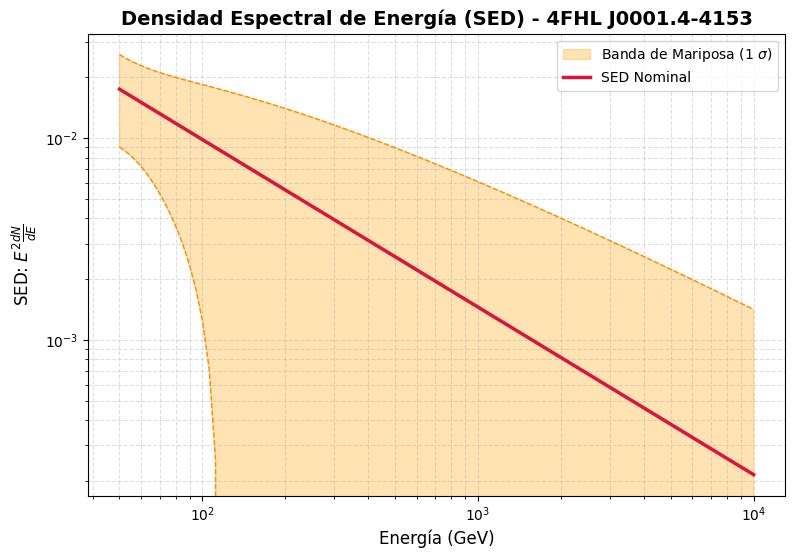

In [ ]:
def graficar_sed_mariposa(nombre_fuente, catalogo):
    # 1. Limpieza de nombres y búsqueda de la fuente (Igual que en el Paso 0)
    nombres = np.array([name.strip() for name in catalogo['Source_Name']])

    if nombre_fuente not in nombres:
        print(f"❌ Error: No se encontró la fuente '{nombre_fuente}'.")
        return

    idx = np.where(nombres == nombre_fuente)[0][0]
    fuente = catalogo[idx]
    print(f"✅ Fuente encontrada para SED: {nombre_fuente}")

    # 2. Configuración para 4FHL (Asumimos PowerLaw y E0 = 50 GeV = 50000 MeV, siendo esta la energía pivote)
    E0 = 50000.0

    # Búsqueda dinámica de las columnas necesarias para la mariposa (Paso 0 ampliado)
    col_pl_index = next((col for col in catalogo.colnames if 'pl_index' in col.lower() or 'index' in col.lower()), None)
    col_err_index = next((col for col in catalogo.colnames if 'unc_pl_index' in col.lower()), None)
    col_flux = next((col for col in catalogo.colnames if 'flux50' in col.lower() and 'unc' not in col.lower()), None)
    col_err_flux = next((col for col in catalogo.colnames if 'unc_flux50' in col.lower()), None)

    # 3. Extracción de los parámetros y sus errores a 1 sigma
    indice = fuente[col_pl_index]
    err_indice = fuente[col_err_index]

    norm = fuente[col_flux]       # Factor de normalización (Flujo)
    err_norm = fuente[col_err_flux] # Error de normalización

    # 4. Rango de energías: Extrapolamos desde 50 GeV hasta 10 TeV (10,000,000 MeV) para ver IACT
    E = np.logspace(np.log10(50000), np.log10(10000000), 100)

    # 5. Cálculo del Flujo Nominal y la SED (E^2 * dN/dE)
    flujo_nominal = norm * (E / E0)**(-indice) # espectro, lo dibujado en el paso 0
    sed_nominal = (E**2) * flujo_nominal

    # 6. Cálculo analítico de la Banda de Mariposa (Equivalente a Fermipy sed())
    # La covarianza entre la normalización y el índice hace que el error crezca al alejarse de E0
    var_log_flujo = (err_norm / norm)**2 + (np.log(E / E0)**2) * (err_indice**2)
    err_sed = sed_nominal * np.sqrt(var_log_flujo)

    sed_superior = sed_nominal + err_sed  # Desviación a +1 sigma
    sed_inferior = sed_nominal - err_sed  # Desviación a -1 sigma

    # 7. Dibujar la SED en escala log-log
    plt.figure(figsize=(9, 6))

    # Dibujar la mariposa (banda conservadora)
    plt.fill_between(E / 1000, sed_inferior, sed_superior, color='orange', alpha=0.3, label='Banda de Mariposa (1 $\sigma$)')

    # Dibujar la SED nominal (optimista)
    plt.plot(E / 1000, sed_nominal, color='crimson', lw=2.5, label='SED Nominal')

    # Límites
    plt.plot(E / 1000, sed_superior, color='darkorange', ls='--', lw=1)
    plt.plot(E / 1000, sed_inferior, color='darkorange', ls='--', lw=1)

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energía (GeV)', fontsize=12)
    plt.ylabel(r'SED: $E^2 \frac{dN}{dE}$', fontsize=12)
    plt.title(f'Densidad Espectral de Energía (SED) - {nombre_fuente}', fontsize=14, fontweight='bold')
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.legend()
    plt.show()

# --- PRUEBA DE LA FUNCIÓN SED ---
nombre_prueba = catalogo['Source_Name'][0].strip()
graficar_sed_mariposa(nombre_prueba, catalogo)

# PASO 2: ESTUDIO DE DETECTABILIDAD

Este estudio es algo más largo que los otros pasos, ya que conlleva varias cosas:
1. Ejecutar un tutorial: Ir a la web de gammapy, buscar el tutorial cta_sensitivity.html y hacerlo funcionar en mi Google Colab para entender cómo lee la librería los ritmos de fondo y las áreas efectivas.
2. Buscar una fuente candidata brillante: Ir al catálogo de Fermi (el que ya tenemos cargado) y buscar una fuente que tenga una significancia brutal, entre 50 y 100 sigmas, para que sea "fácil" de detectar como prueba.
3. Unir mis datos con Gammapy: Coger el espectro de esa fuente (tu flujo y tu banda de mariposa conservadora) y meterlo en el código de gammapy.
4. Despejar el tiempo: Modificar el código del tutorial para que, sabiendo que quieres un S/N de 5 sigmas, el programa te devuelva cuál es el $T_{obs}$ (tiempo de observación en horas) que necesitará el telescopio Cherenkov para detectarla.

### 1. Instalación de Gammapy y preparación de datos

Instalamos la librería gammapy y descargamos directamente el archivo de funciones de respuesta (IRFs) de los futuros telescopios CTA, que es lo que pide el tutorial oficial.

In [ ]:
# 1. Instalamos gammapy forzando versiones compatibles de regions y astropy
!pip install "numpy<2.0.0" "matplotlib<3.9.0" astropy==6.0.0 regions==0.8 gammapy

# 2. Descargamos el archivo oficial de calibración (IRF) de CTA-South usado en el tutorial
!wget -nc https://raw.githubusercontent.com/gammapy/gammapy-data/master/cta-1dc/caldb/data/cta/1dc/bcf/South_z20_50h/irf_file.fits
print("\n¡Gammapy instalado y datos de CTA descargados con éxito!")

File ‘irf_file.fits’ already there; not retrieving.


¡Gammapy instalado y datos de CTA descargados con éxito!


### 2. Buscar una fuente brillante en el 4FHL

Buscamos en el catálogo una fuente que tenga una significancia de entre 50 y 100 sigmas (brillante). La significancia de una fuente equivale matemáticamente a la raíz cuadrada de su valor TS (Test Statistic).

In [ ]:
import numpy as np
from astropy.io import fits
from astropy.table import Table

# 1. Asegúrate de haber subido tu archivo '4FHL_catalog.fit' a este nuevo Colab, o descárgalo de nuevo
!wget -nc --no-check-certificate -O 4FHL_catalog.fit https://fermi.gsfc.nasa.gov/ssc/data/access/lat/4FHL/gll_psch_v14.fit

# 2. Abrimos el catálogo y leemos la tabla con Table.read() para que Astropy conserve las UNIDADES reales del FITS
catalogo = Table.read("4FHL_catalog.fit", hdu=1)

# 3. Buscamos fuentes con S/N entre 50 y 100 sigmas (es decir, TS entre 2500 y 10000)
fuentes_brillantes = catalogo[(catalogo['TS'] >= 2500) & (catalogo['TS'] <= 10000)]
print(f"Se han encontrado {len(fuentes_brillantes)} fuentes brillantes en este rango.")

# 4. Elegimos la primera fuente de la lista para nuestro estudio
fuente_elegida = fuentes_brillantes[0]
nombre_fuente = fuente_elegida['Source_Name'].strip()
indice = float(fuente_elegida['PL_Index'])  # Índice espectral en el 4FHL

# 5. Calculamos el FLUJO DIFERENCIAL (N0) y la ENERGÍA PIVOTE (E0 = 50 GeV) a partir de Flux50
# El catálogo 4FHL no trae Flux_Density ni Pivot_Energy, solo el flujo integral entre 50 y 2000 GeV (por eso no lo hacemos con eso)
flux50 = float(fuente_elegida['Flux50']) * u.Unit("1 / (cm2 s)")
e_pivote = 50.0 * u.GeV
e_max = 2000.0 * u.GeV
norm_diferencial = (flux50 * (indice - 1)) / (e_pivote * (1 - (e_max / e_pivote)**(1 - indice)))

print(f"\n--- FUENTE SELECCIONADA PARA EL ESTUDIO ---")
print(f"Nombre: {nombre_fuente}")
print(f"Índice espectral: {indice:.2f}")
print(f"Normalización diferencial (N0): {norm_diferencial.to('1 / (cm2 s TeV)'):.3e}")
print(f"Energía pivote (E0):            {e_pivote}")

File ‘4FHL_catalog.fit’ already there; not retrieving.


Se han encontrado 5 fuentes brillantes en este rango.

--- FUENTE SELECCIONADA PARA EL ESTUDIO ---
Nombre: 4FHL J0534.5+2201e
Índice espectral: 2.05
Normalización diferencial (N0): 2.574e-08 1 / (TeV s cm2)
Energía pivote (E0):            50.0 GeV


Resulta que esta fuente que hemos seleccionado es la Nebulosa del Cangrejo, una fuente conocida.

### 3. Estudio de Detectabilidad con Gammapy

(Son los minipasos 3 y 4). Vamos a simular el ritmo del fondo o background ($R_{off}$) y el ritmo de la fuente ($R_{exc}$) para 1 hora con gammapy, y luego haremos un bucle para ver cómo crece la curva de Señal/Ruido (S/N) con el tiempo ($T_{obs}$) hasta cruzar la línea de las 5 sigmas.

Nuestro código no es exactamente como el tutorial de Gammapy porque en ese calculaban la sensibilidad del telescopio: le daban a la función un tiempo de observación muy grande y buscaban cuál era el flujo más débil que podían detectar. Nosotros, sin embargo, ya conocemos el flujo de nuestra fuente brillante, y lo que queremos obtener es el tiempo de observación mínimo para obtener una significancia de $5σ$.

--- RITMOS BASE (Para 1 hora de observación) ---
Fotones de exceso de la fuente (R_exc): 6087.56 fotones/hora
Fotones del ruido de fondo (R_off):     420.62 fotones/hora

🚀 RESULTADO: El telescopio CTA necesitaría 6.2048 segundos de exposición para detectar la fuente a 5 sigmas.


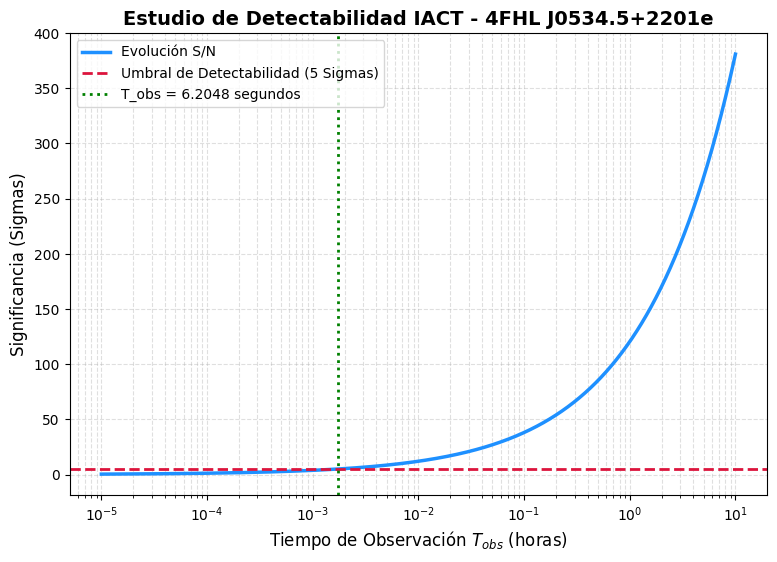

In [ ]:
import astropy.units as u
from astropy.coordinates import SkyCoord, EarthLocation
from regions import CircleSkyRegion
from gammapy.data import FixedPointingInfo, Observation
from gammapy.datasets import SpectrumDataset, SpectrumDatasetOnOff
from gammapy.makers import SpectrumDatasetMaker
from gammapy.maps import MapAxis, RegionGeom
from gammapy.irf import load_irf_dict_from_file
from gammapy.modeling.models import PowerLawSpectralModel, SkyModel
from gammapy.stats import WStatCountsStatistic
import matplotlib.pyplot as plt

# 1. Cargar las funciones de respuesta de los telescopios CTA (IRFs)
irfs = load_irf_dict_from_file("irf_file.fits")
# ubicacion_cta = observatory_locations["ctao_south"] --> no funciona, porque usamos una versión Gammapy antigua para que sea compatible con las librerías de astropy y regions
# ---> SOLUCIÓN: usamos las coordenadas geográficas exactas de CTA-South
ubicacion_cta = EarthLocation(lon=-70.316 * u.deg, lat=-24.683 * u.deg, height=2150 * u.m)

# 2. Configurar la observación base (1 hora)
tiempo_base = 1.0 * u.h
apuntamiento = SkyCoord(ra=0 * u.deg, dec=0 * u.deg) # Apuntamos al centro para la simulación
info_apuntamiento = FixedPointingInfo(fixed_icrs=apuntamiento)

obs = Observation.create(pointing=info_apuntamiento, irfs=irfs, livetime=tiempo_base, location=ubicacion_cta)

# 3. Definir la geometría y las energías (según el tutorial de Gammapy)
eje_energia = MapAxis.from_energy_bounds(0.05 * u.TeV, 2 * u.TeV, nbin=10)
eje_energia_real = MapAxis.from_energy_bounds(0.01 * u.TeV, 10 * u.TeV, nbin=30, name="energy_true")

# Extraemos los datos de un círculo de 0.1 grados
offset = 0.0 * u.deg # Nuestra fuente está en el centro del apuntamiento
radio_region_on = 0.1 * u.deg # Guardamos el radio en una variable para usarlo en la corrección del fondo
region_on = CircleSkyRegion(center=apuntamiento, radius=0.1 * u.deg)
geom = RegionGeom.create(region_on, axes=[eje_energia])
dataset_vacio = SpectrumDataset.create(geom=geom, energy_axis_true=eje_energia_real)

# 4. Crear el Dataset de Gammapy (calcula el Área Efectiva y el Fondo simulado de CTA)
creador = SpectrumDatasetMaker(
    selection=["exposure", "edisp", "background"],
    containment_correction=False) # Desactivamos la corrección automática para hacerla al 68% (Aplicamos nuestra propia containment correction)
dataset = creador.run(dataset_vacio, obs)
# Corrección de la PSF al 68% (según el tutorial de Gammapy)
containment = 0.68
dataset.exposure *= containment
# Corregimos el fondo
radios_on = obs.psf.containment_radius(energy_true=eje_energia.center, offset=offset, fraction=containment)
factor = (1 - np.cos(radios_on)) / (1 - np.cos(radio_region_on))
dataset.background *= factor.value.reshape((-1, 1, 1))

# 5. Modelar nuestra fuente usando los datos de Fermi (Paso 0)
# 5. Modelar nuestra fuente usando los datos calibrados de Fermi con unidades de Astropy
modelo_espectral = PowerLawSpectralModel(
    index=indice,
    amplitude=norm_diferencial.to("1 / (cm2 s TeV)"), # Convertimos explícitamente a las unidades que espera CTA/Gammapy
    reference=e_pivote.to("TeV"))                    # Convertimos la energía pivote a TeV
modelo_cielo = SkyModel(spectral_model=modelo_espectral, name=nombre_fuente)
dataset.models = [modelo_cielo]

# 6. Extraer los Ritmos Base (R_exc y R_off) para 1 hora ---> a partir de los ritmos (fotones/h) podremos obtener el N_fotones para cada intervalo de tiempo
# npred_signal suma los fotones teóricos de nuestra fuente
# npred_background suma los fotones teóricos del ruido
n_senal_1h = dataset.npred_signal().data.sum()      # OJO, aquí gammapy está haciendo la integral del espectro (flujo) por el Aeff, calculando el Rexc (ritmo de exceso)
n_fondo_1h = dataset.npred_background().data.sum()  # OJO, y aquí gammapy está haciendo la simulación del fondo (ruido), para calcular Roff (ritmo de fondo)
alpha = 0.2 # Factor estándar de escala entre la región OFF (fondo) y la ON (fuente)

print(f"--- RITMOS BASE (Para 1 hora de observación) ---")
print(f"Fotones de exceso de la fuente (R_exc): {n_senal_1h:.2f} fotones/hora")
print(f"Fotones del ruido de fondo (R_off):     {n_fondo_1h:.2f} fotones/hora")

# 7. Bucle de Detectabilidad: Damos valores a T_obs hasta hallar 5 sigmas
tiempos_prueba = np.logspace(-5, 1, 10000) # Probamos 10.000 valores desde 10^-5 horas (0.036 segundos) hasta 10^1 horas (10 horas)
# Escalamos los tiempos en escala logarítmica para incluir un mayor rango (por si el tiempo es muy pequeño)
significancias = []
t_detectabilidad_horas = None

for t in tiempos_prueba:
    # El número de fotones crece con el tiempo (N = Ritmo * T_obs)
    n_on = (n_senal_1h + n_fondo_1h) * t
    n_off = (n_fondo_1h * t) / alpha

    # Usamos la estadística de Li & Ma implementada en Gammapy
    estadistica = WStatCountsStatistic(n_on=n_on, n_off=n_off, alpha=alpha)
    sigmas = estadistica.sqrt_ts # Esto nos da el Signal-to-Noise Ratio (S/N)
    significancias.append(sigmas)

    # Encontramos el momento exacto en el que pasamos el umbral de 5 sigmas
    if sigmas >= 5.0 and t_detectabilidad_horas is None:
        t_detectabilidad_horas = t

# Conversión de horas a minutos/segundos para el texto de salida (solo si no es conveniente expresarlo en horas)
if t_detectabilidad_horas < 1:
    t_minutos = t_detectabilidad_horas * 60
    if t_minutos < 1:
        t_segundos = t_minutos * 60
        texto_resultado = f"{t_segundos:.4f} segundos"
    else:
        texto_resultado = f"{t_minutos:.1f} minutos"
else:
    texto_resultado = f"{t_detectabilidad_horas:.2f} horas"

print(f"\n🚀 RESULTADO: El telescopio CTA necesitaría {texto_resultado} de exposición para detectar la fuente a 5 sigmas.")

# 8. Dibujar la curva S/N en función del tiempo
plt.figure(figsize=(9, 6))
plt.plot(tiempos_prueba, significancias, color='dodgerblue', lw=2.5, label='Evolución S/N')
plt.axhline(5, color='crimson', ls='--', lw=2, label='Umbral de Detectabilidad (5 Sigmas)')

if t_detectabilidad_horas:
    plt.axvline(t_detectabilidad_horas, color='green', ls=':', lw=2, label=f'T_obs = {texto_resultado}')

plt.xscale('log')
plt.xlabel('Tiempo de Observación $T_{obs}$ (horas)', fontsize=12)
plt.ylabel('Significancia (Sigmas)', fontsize=12)
plt.title(f'Estudio de Detectabilidad IACT - {nombre_fuente}', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.4)
plt.show()

Hemos obtenido que para detectar una fuente tan brillante como la Nebulosa del Cangrejo mediante los futuros telescopios CTAO necesitaremos un tiempo de 6.2048s. Nuestro valor del $T_{obs}$ es consistente con el valor tabulado para telescopios Cherenkov: de 5 a 15s típicamente.

**Relación $R_{exc}$ y $R_{off}$:** El ritmo de señal ($6087.56\text{ ph/h}$) es $\sim 14$ veces superior al fondo ($420.62\text{ ph/h}$). Aunque en fuentes más débiles $R_{exc}$ suele ser del orden de $R_{off}$ o inferior, este valor tan alto de $R_{exc}$ es esperado al tratarse de la fuente estacionaria más brillante del cielo en muy altas energías (candela estándar).

El valor del tiempo de observación que hemos obtenido es tan pequeño porque el espectro de la Nebulosa del Cangrejo sigue una log-parabola en vez de una power-law, y también por las siguientes razones:
* **La gran área efectiva del CTA-South:** mientras que los telescopios Cherenkov actuales (MAGIC, H.E.S.S.) detectan la Nebulosa del Cangrejo a $5\sigma$ en $\sim 1\text{–}2$ minutos, CTAO-South reduce este tiempo a unos pocos segundos gracias a su enorme área efectiva ($\sim 10^5\text{ m}^2$ frente a $\sim 1\text{ m}^2$ de Fermi-LAT).

* **Limitaciones del modelo:** El tiempo calculado corresponde al tiempo de exposición teórico (*livetime*) sin contar tiempos operativos del telescopio (apuntamiento y calibración).

* Además, no se incluye **absorción por EBL** (extinción extragaláctica), aunque esto es irrelevante para el Cangrejo por ser una fuente galáctica (tan cerca de nosotros, no se produce extinción, porque el redshift z es muy bajo), pero es necesario tenerlo en cuenta si se aplica este código a fuentes extragalácticas. Para estas, el tiempo se verá reducido erróneamente por no incluir la extinción.

